<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/general_relativity/gr_colab_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*General Relativity* — `gr_colab_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# General Relativity — Interactive Visualisations
**PSE Lab · SeoulTech**

Seven visualisations covering all six chapters of the *General Relativity* course (Tong lectures).

| # | Visualisation | Chapter |
|---|---|---|
| 1 | Schwarzschild Effective Potential & Geodesic Types | Ch 1 & 6 |
| 2 | Metric on S² — Components & Christoffel Symbols | Ch 2 |
| 3 | Parallel Transport on S² — Holonomy | Ch 3 |
| 4 | de Sitter Spacetime — Static Patch & Penrose Diagram | Ch 4 |
| 5 | Gravitational Wave Polarisations h₊ and h× | Ch 5 |
| 6 | Finkelstein Diagram — Light Cones at the Horizon | Ch 6 |
| 7 | Kerr Black Hole — Ergoregion Cross-Section | Ch 6 |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D
import warnings
warnings.filterwarnings('ignore')

BG      = '#0d1117'
SURFACE = '#161b22'
BORDER  = '#30363d'
TEXT    = '#e6edf3'
MUTED   = '#8b949e'
GOLD    = '#d4a017'
BLUE    = '#388bfd'
GREEN   = '#3fb950'
RED     = '#f85149'
PURPLE  = '#bc8cff'
ORANGE  = '#f0883e'

plt.rcParams.update({
    'figure.facecolor': BG,   'axes.facecolor': SURFACE,
    'axes.edgecolor':   BORDER,'axes.labelcolor': TEXT,
    'xtick.color': MUTED,      'ytick.color': MUTED,
    'text.color':  TEXT,       'grid.color': BORDER,
    'grid.linestyle': '--',    'grid.alpha': 0.4,
    'legend.facecolor': SURFACE,'legend.edgecolor': BORDER,
    'font.size': 11, 'axes.titlesize': 12, 'axes.titlecolor': GOLD,
})
print('Setup complete.')

Setup complete.


## Plot 1 — Schwarzschild Effective Potential (Ch 1 & 6)

Physics: $V_\mathrm{eff}(r) = -GM/r + L^2/(2r^2) - GML^2/r^3$ (massive particle); $= L^2/(2r^2) - GML^2/r^3$ (photon). With $G=M=1$: $r_s=2$, ISCO at $r=6GM$, photon sphere at $r=3GM$.

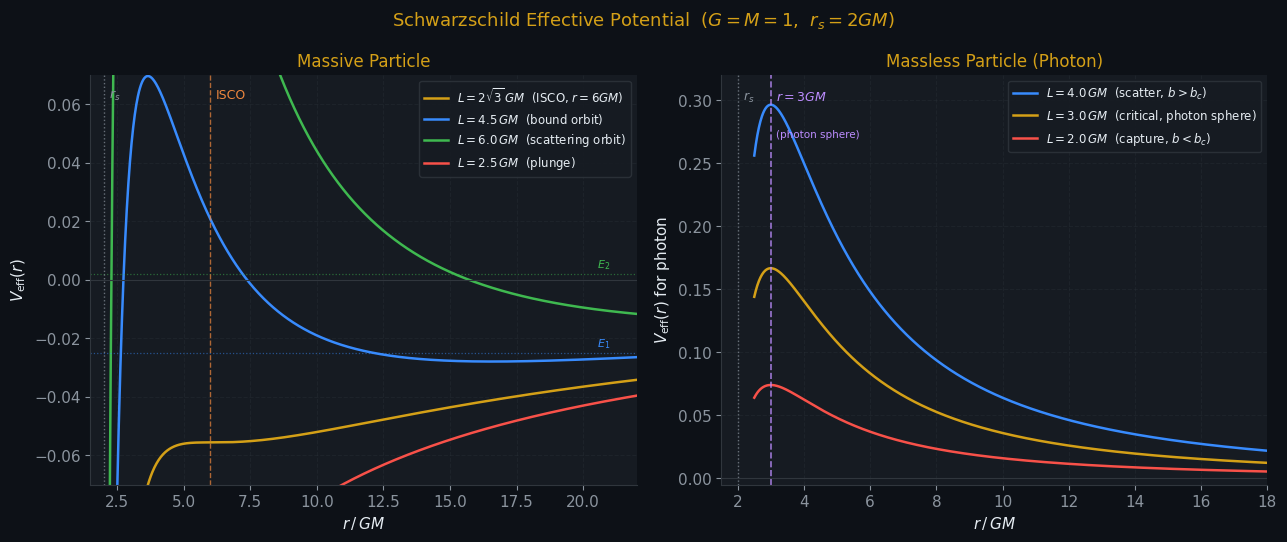

Saved: gr_fig01_veff.png


In [2]:
G, M = 1.0, 1.0
rs = 2*G*M

def Veff_massive(r, L):
    return -G*M/r + L**2/(2*r**2) - G*M*L**2/r**3

def Veff_photon(r, L):
    return L**2/(2*r**2) - G*M*L**2/r**3

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(r'Schwarzschild Effective Potential  ($G = M = 1$,  $r_s = 2GM$)',
             color=GOLD, fontsize=13)

# ── Left: massive particle ──────────────────────────────────────────
ax = axes[0]
r = np.linspace(2.05, 22, 1000)

# L_ISCO = 2*sqrt(3)*GM
params = [
    (2*np.sqrt(3), GOLD,   r'$L = 2\sqrt{3}\,GM$  (ISCO, $r=6GM$)'),
    (4.5,          BLUE,   r'$L = 4.5\,GM$  (bound orbit)'),
    (6.0,          GREEN,  r'$L = 6.0\,GM$  (scattering orbit)'),
    (2.5,          RED,    r'$L = 2.5\,GM$  (plunge)'),
]
for L, col, lab in params:
    ax.plot(r, Veff_massive(r, L), color=col, lw=1.8, label=lab)

ax.axhline(-0.025, color=BLUE,  lw=0.9, ls=':', alpha=0.5)
ax.axhline( 0.002, color=GREEN, lw=0.9, ls=':', alpha=0.5)
ax.text(20.5, -0.023, r'$E_1$', color=BLUE,  fontsize=8)
ax.text(20.5,  0.004, r'$E_2$', color=GREEN, fontsize=8)
ax.axvline(rs,    color=MUTED,  lw=1.0, ls=':', alpha=0.7)
ax.axvline(6*G*M, color=ORANGE, lw=1.0, ls='--', alpha=0.7)
ax.text(rs+0.2,    0.062, r'$r_s$',  color=MUTED,  fontsize=9)
ax.text(6*G*M+0.2, 0.062, 'ISCO',   color=ORANGE, fontsize=9)
ax.axhline(0, color=BORDER, lw=0.8)
ax.set_xlim(1.5, 22)
ax.set_ylim(-0.07, 0.07)
ax.set_xlabel(r'$r\,/\,GM$')
ax.set_ylabel(r'$V_\mathrm{eff}(r)$')
ax.set_title('Massive Particle')
ax.legend(fontsize=8.5, loc='upper right')
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_color(BORDER); ax.spines['left'].set_color(BORDER)

# ── Right: photon ───────────────────────────────────────────────────
ax2 = axes[1]
r2 = np.linspace(2.5, 18, 1000)

for L, col, lab in [
    (4.0, BLUE,   r'$L = 4.0\,GM$  (scatter, $b > b_c$)'),
    (3.0, GOLD,   r'$L = 3.0\,GM$  (critical, photon sphere)'),
    (2.0, RED,    r'$L = 2.0\,GM$  (capture, $b < b_c$)'),
]:
    ax2.plot(r2, Veff_photon(r2, L), color=col, lw=1.8, label=lab)

ax2.axvline(rs,    color=MUTED,  lw=1.0, ls=':', alpha=0.7)
ax2.axvline(3*G*M, color=PURPLE, lw=1.2, ls='--', alpha=0.8)
ax2.text(rs+0.15,    0.30, r'$r_s$',         color=MUTED,  fontsize=9)
ax2.text(3*G*M+0.15, 0.30, r'$r=3GM$',       color=PURPLE, fontsize=9)
ax2.text(3*G*M+0.15, 0.27, '(photon sphere)', color=PURPLE, fontsize=7.5)
ax2.axhline(0, color=BORDER, lw=0.8)
ax2.set_xlim(1.5, 18)
ax2.set_ylim(-0.005, 0.32)
ax2.set_xlabel(r'$r\,/\,GM$')
ax2.set_ylabel(r'$V_\mathrm{eff}(r)$ for photon')
ax2.set_title('Massless Particle (Photon)')
ax2.legend(fontsize=8.5, loc='upper right')
ax2.grid(True, alpha=0.3)
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
ax2.spines['bottom'].set_color(BORDER); ax2.spines['left'].set_color(BORDER)

plt.tight_layout()
plt.savefig('gr_fig01_veff.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: gr_fig01_veff.png')

## Plot 2 — Metric on S² : Components & Christoffel Symbols (Ch 2)

Physics: $ds^2 = d\theta^2 + \sin^2\!\theta\,d\varphi^2$. Non-zero Christoffel symbols: $\Gamma^\theta_{\varphi\varphi}=-\sin\theta\cos\theta$, $\Gamma^\varphi_{\theta\varphi}=\cot\theta$.

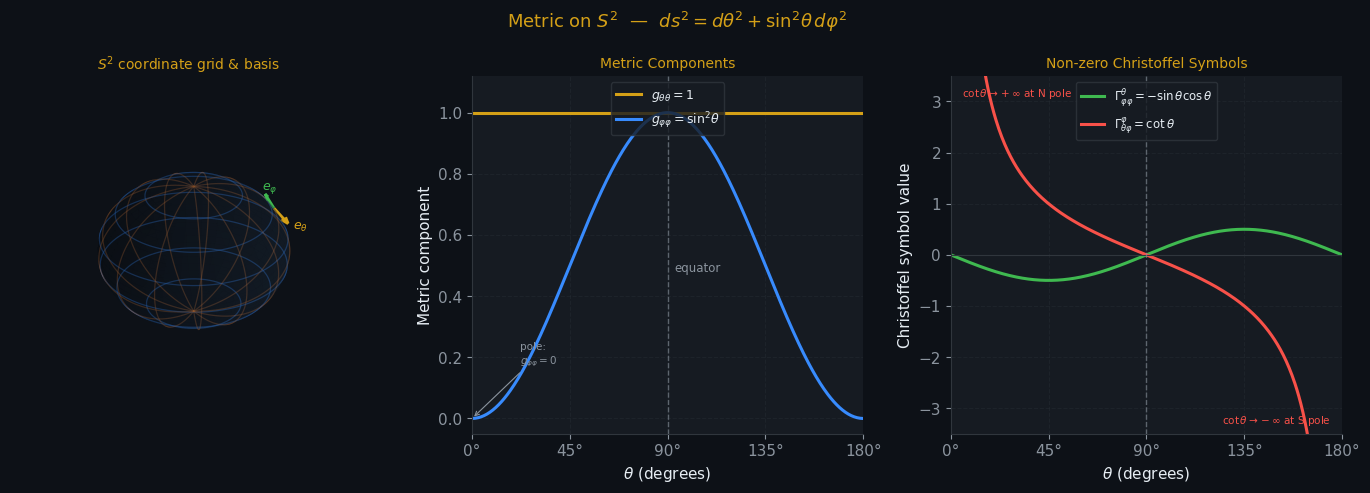

Saved: gr_fig02_metric_s2.png


In [3]:
fig = plt.figure(figsize=(14, 5))
fig.patch.set_facecolor(BG)
fig.suptitle(r'Metric on $S^2$  —  $ds^2 = d\theta^2 + \sin^2\!\theta\, d\varphi^2$',
             color=GOLD, fontsize=13)

ax3d = fig.add_subplot(131, projection='3d')
ax3d.set_facecolor(BG)
ax_g  = fig.add_subplot(132)
ax_g.set_facecolor(SURFACE)
ax_ch = fig.add_subplot(133)
ax_ch.set_facecolor(SURFACE)

# ── 3D sphere ──────────────────────────────────────────────────────
u = np.linspace(0, np.pi, 35)
v = np.linspace(0, 2*np.pi, 70)
ax3d.plot_surface(np.outer(np.sin(u), np.cos(v)),
                  np.outer(np.sin(u), np.sin(v)),
                  np.outer(np.cos(u), np.ones_like(v)),
                  color='#1c2a3a', alpha=0.25, linewidth=0)

for th in np.linspace(np.pi/6, 5*np.pi/6, 6):
    ph = np.linspace(0, 2*np.pi, 120)
    ax3d.plot(np.sin(th)*np.cos(ph), np.sin(th)*np.sin(ph),
              np.cos(th)*np.ones_like(ph), color=BLUE, alpha=0.45, lw=0.9)
for ph0 in np.linspace(0, 2*np.pi, 13, endpoint=False):
    th2 = np.linspace(0, np.pi, 80)
    ax3d.plot(np.sin(th2)*np.cos(ph0), np.sin(th2)*np.sin(ph0),
              np.cos(th2), color=ORANGE, alpha=0.35, lw=0.9)

# Basis vectors at (θ=π/3, φ=π/4)
th0, ph0 = np.pi/3, np.pi/4
p0  = np.array([np.sin(th0)*np.cos(ph0), np.sin(th0)*np.sin(ph0), np.cos(th0)])
e_th = np.array([np.cos(th0)*np.cos(ph0), np.cos(th0)*np.sin(ph0), -np.sin(th0)])
e_ph = np.array([-np.sin(ph0), np.cos(ph0), 0.0])
sc = 0.32
ax3d.quiver(*p0, *(sc*e_th), color=GOLD,  arrow_length_ratio=0.35, lw=2)
ax3d.quiver(*p0, *(sc*e_ph), color=GREEN, arrow_length_ratio=0.35, lw=2)
ax3d.text(*(p0+sc*e_th*1.35), r'$e_\theta$',   color=GOLD,  fontsize=9)
ax3d.text(*(p0+sc*e_ph*1.35), r'$e_\varphi$',  color=GREEN, fontsize=9)

ax3d.set_xlim(-1.2, 1.2); ax3d.set_ylim(-1.2, 1.2); ax3d.set_zlim(-1.2, 1.2)
ax3d.set_title(r'$S^2$ coordinate grid & basis', color=GOLD, pad=4, fontsize=10)
ax3d.set_axis_off()

# ── Metric components ──────────────────────────────────────────────
theta = np.linspace(0.01, np.pi - 0.01, 400)
ax_g.plot(np.degrees(theta), np.ones_like(theta),  color=GOLD, lw=2.2,
          label=r'$g_{\theta\theta} = 1$')
ax_g.plot(np.degrees(theta), np.sin(theta)**2,      color=BLUE, lw=2.2,
          label=r'$g_{\varphi\varphi} = \sin^2\!\theta$')
ax_g.axvline(90, color=MUTED, ls='--', lw=1.0, alpha=0.6)
ax_g.text(93, 0.48, 'equator', color=MUTED, fontsize=8.5)
ax_g.annotate('pole:\n$g_{\\varphi\\varphi}=0$', xy=(0, 0), xytext=(22, 0.18),
    arrowprops=dict(arrowstyle='->', color=MUTED, lw=0.8), color=MUTED, fontsize=7.5)
ax_g.set_xlim(0, 180); ax_g.set_ylim(-0.05, 1.12)
ax_g.set_xlabel(r'$\theta$ (degrees)')
ax_g.set_ylabel('Metric component')
ax_g.set_title('Metric Components', fontsize=10)
ax_g.set_xticks([0,45,90,135,180])
ax_g.set_xticklabels(['0°','45°','90°','135°','180°'])
ax_g.legend(fontsize=9, loc='upper center')
ax_g.grid(True, alpha=0.3)
ax_g.spines['top'].set_visible(False); ax_g.spines['right'].set_visible(False)
ax_g.spines['bottom'].set_color(BORDER); ax_g.spines['left'].set_color(BORDER)

# ── Christoffel symbols ────────────────────────────────────────────
th_inner = theta[10:-10]
ax_ch.plot(np.degrees(theta),    -np.sin(theta)*np.cos(theta),         color=GREEN, lw=2.2,
           label=r'$\Gamma^\theta_{\varphi\varphi} = -\sin\theta\cos\theta$')
ax_ch.plot(np.degrees(th_inner), np.cos(th_inner)/np.sin(th_inner),   color=RED,   lw=2.2,
           label=r'$\Gamma^\varphi_{\theta\varphi} = \cot\theta$')
ax_ch.axhline(0,  color=BORDER, lw=0.8)
ax_ch.axvline(90, color=MUTED,  ls='--', lw=1.0, alpha=0.6)
ax_ch.set_xlim(0, 180); ax_ch.set_ylim(-3.5, 3.5)
ax_ch.set_xlabel(r'$\theta$ (degrees)')
ax_ch.set_ylabel('Christoffel symbol value')
ax_ch.set_title('Non-zero Christoffel Symbols', fontsize=10)
ax_ch.set_xticks([0,45,90,135,180])
ax_ch.set_xticklabels(['0°','45°','90°','135°','180°'])
ax_ch.legend(fontsize=8.5, loc='upper center')
ax_ch.grid(True, alpha=0.3)
ax_ch.spines['top'].set_visible(False); ax_ch.spines['right'].set_visible(False)
ax_ch.spines['bottom'].set_color(BORDER); ax_ch.spines['left'].set_color(BORDER)
ax_ch.text(5,  3.1, r'$\cot\theta\to+\infty$ at N pole', color=RED, fontsize=7.5)
ax_ch.text(175,-3.3, r'$\cot\theta\to-\infty$ at S pole', color=RED, fontsize=7.5, ha='right')

plt.tight_layout()
plt.savefig('gr_fig02_metric_s2.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: gr_fig02_metric_s2.png')

## Plot 3 — Parallel Transport on S² : Holonomy (Ch 3)

Physics: Transporting a vector around a closed triangular loop $N\to A\to B\to N$ on the unit sphere encloses solid angle $\Omega = \Delta\varphi$. The vector rotates by $\Delta\alpha = \Omega$ — this is the holonomy, equal to the integrated Gaussian curvature $K=1$ over the enclosed area.

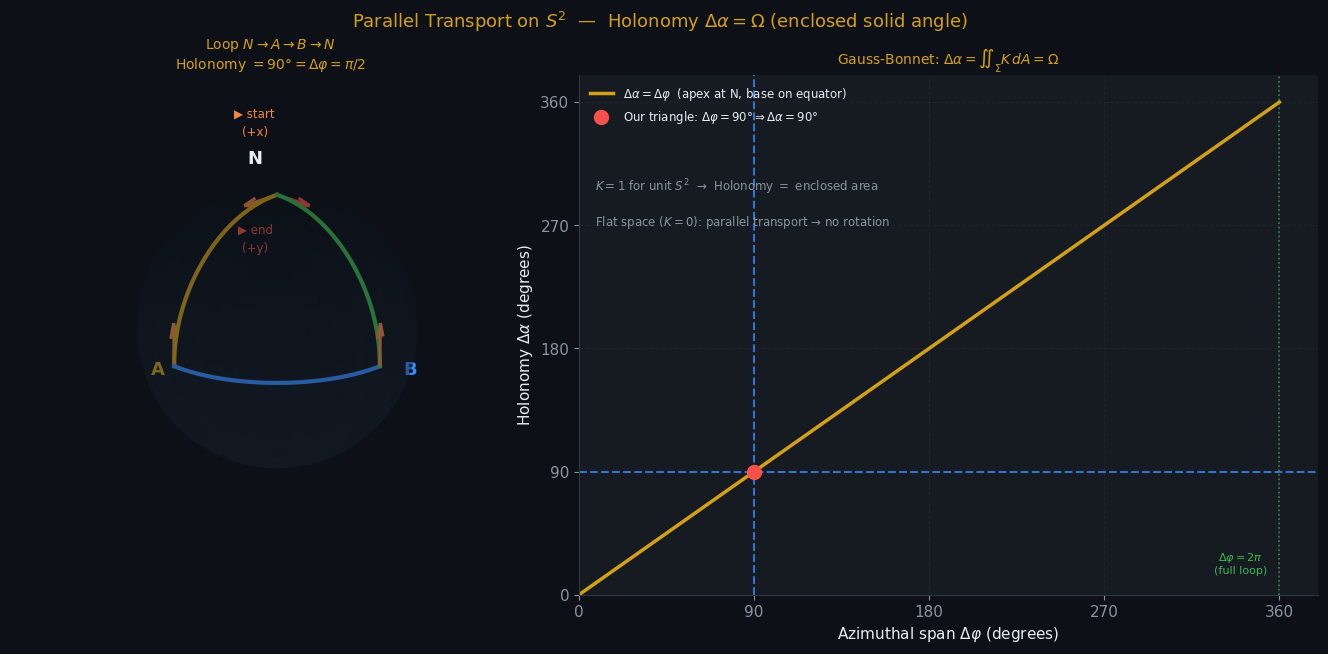

Saved: gr_fig03_parallel_transport.png


In [4]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(14, 6.5))
fig.patch.set_facecolor(BG)
fig.suptitle(r'Parallel Transport on $S^2$  —  Holonomy $\Delta\alpha = \Omega$ (enclosed solid angle)',
             color=GOLD, fontsize=13, y=0.98)

# 3D panel: wider left column
gs = GridSpec(1, 2, figure=fig, width_ratios=[1.2, 1.5], wspace=0.02,
              left=0.01, right=0.97, top=0.88, bottom=0.08)
ax3d = fig.add_subplot(gs[0], projection='3d')
ax3d.set_facecolor(BG)
ax2  = fig.add_subplot(gs[1])
ax2.set_facecolor(SURFACE)

# ── 3D sphere ────────────────────────────────────────────────
u = np.linspace(0, np.pi, 40)
v = np.linspace(0, 2*np.pi, 80)
ax3d.plot_surface(np.outer(np.sin(u), np.cos(v)),
                  np.outer(np.sin(u), np.sin(v)),
                  np.outer(np.cos(u), np.ones_like(v)),
                  color='#1c2a3a', alpha=0.25, linewidth=0)

# Loop legs: N→A (meridian at φ=0), A→B (equator), B→N (meridian at φ=π/2)
th1 = np.linspace(0, np.pi/2, 80)
ax3d.plot(np.sin(th1), np.zeros_like(th1), np.cos(th1), color=GOLD,  lw=3.0, zorder=5)
ph2 = np.linspace(0, np.pi/2, 80)
ax3d.plot(np.cos(ph2), np.sin(ph2),  np.zeros_like(ph2), color=BLUE,  lw=3.0, zorder=5)
th3 = np.linspace(np.pi/2, 0, 80)
ax3d.plot(np.zeros_like(th3), np.sin(th3), np.cos(th3), color=GREEN, lw=3.0, zorder=5)

# Parallel-transported vectors (ORANGE = en route, RED = final at N)
sc = 0.32
def qarrow(ax, pos, vec, col):
    ax.quiver(*pos, *vec, color=col, lw=2.2,
              arrow_length_ratio=0.35, normalize=True, length=sc)

qarrow(ax3d, [0,   0,   1.0], [1, 0, 0], ORANGE)  # N start → +x
qarrow(ax3d, [1.0, 0,   0  ], [0, 0, 1], ORANGE)  # A: +z
qarrow(ax3d, [0,   1.0, 0  ], [0, 0, 1], ORANGE)  # B: +z
qarrow(ax3d, [0,   0,   1.0], [0, 1, 0], RED)     # N end → +y (90° rotated)

# Vertex labels — kept close to vertex, no overlap with arrows
ax3d.text( 0.0, -0.22, 1.18, 'N',          color=TEXT,   fontsize=13, fontweight='bold', ha='center')
ax3d.text( 1.22,  0.0,  0.0, 'A',          color=GOLD,   fontsize=13, fontweight='bold')
ax3d.text( 0.0,   1.22, 0.0, 'B',          color=BLUE,   fontsize=13, fontweight='bold')
ax3d.text( 0.0,  -0.22, 1.52, '\u25b6 start',  color=ORANGE, fontsize=8.5, ha='center')
ax3d.text( 0.0,  -0.22, 1.38, '(+x)',       color=ORANGE, fontsize=8.5, ha='center')
ax3d.text( 0.0,  -0.22, 0.66, '\u25b6 end',    color=RED,    fontsize=8.5, ha='center')
ax3d.text( 0.0,  -0.22, 0.52, '(+y)',       color=RED,    fontsize=8.5, ha='center')

ax3d.set_xlim(-1.1, 1.1)
ax3d.set_ylim(-1.1, 1.1)
ax3d.set_zlim(-1.1, 1.1)
ax3d.set_box_aspect([1, 1, 1])
ax3d.view_init(elev=22, azim=45)   # viewpoint: sphere fills panel nicely
ax3d.set_title('Loop $N\\to A\\to B\\to N$\n'
               r'Holonomy $= 90° = \Delta\varphi = \pi/2$',
               color=GOLD, fontsize=10, pad=4)
ax3d.set_axis_off()

# ── Right: holonomy = Δφ graph ──────────────────────────────────────
dphi = np.linspace(0, 2*np.pi, 300)

ax2.plot(np.degrees(dphi), np.degrees(dphi), color=GOLD, lw=2.5,
         label=r'$\Delta\alpha = \Delta\varphi$  (apex at N, base on equator)')
ax2.axvline(90, color=BLUE, ls='--', lw=1.5, alpha=0.8)
ax2.axhline(90, color=BLUE, ls='--', lw=1.5, alpha=0.8)
ax2.scatter([90], [90], color=RED, s=100, zorder=6,
            label=r'Our triangle: $\Delta\varphi=90°\Rightarrow\Delta\alpha=90°$')
ax2.axvline(360, color=GREEN, ls=':', lw=1.2, alpha=0.7)
# Δφ=2π label: inside plot area to avoid cutoff
ax2.text(340, 15, r'$\Delta\varphi=2\pi$' + '\n(full loop)',
         color=GREEN, fontsize=8, ha='center')

ax2.set_xlim(0, 380)
ax2.set_ylim(0, 380)
ax2.set_xticks([0, 90, 180, 270, 360])
ax2.set_yticks([0, 90, 180, 270, 360])
ax2.set_xlabel(r'Azimuthal span $\Delta\varphi$ (degrees)', fontsize=11)
ax2.set_ylabel(r'Holonomy $\Delta\alpha$ (degrees)', fontsize=11)
ax2.set_title(r'Gauss-Bonnet: $\Delta\alpha = \iint_\Sigma K\,dA = \Omega$', fontsize=10)
# No frame, no background box on legend
ax2.legend(fontsize=8.5, loc='upper left', frameon=False)
ax2.grid(True, alpha=0.3)
ax2.spines['top'].set_visible(False);  ax2.spines['right'].set_visible(False)
ax2.spines['bottom'].set_color(BORDER); ax2.spines['left'].set_color(BORDER)

# Insight text: no bbox, just plain text to avoid dark box
ax2.text(8, 295,
    r'$K = 1$ for unit $S^2$  →  Holonomy $=$ enclosed area',
    color=MUTED, fontsize=8.5)
ax2.text(8, 270,
    r'Flat space ($K=0$): parallel transport → no rotation',
    color=MUTED, fontsize=8.5)

plt.savefig('gr_fig03_parallel_transport.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: gr_fig03_parallel_transport.png')


## Plot 4 — de Sitter Spacetime: Static Patch & Penrose Diagram (Ch 4)

Physics: $f^2(r) = 1 - r^2/R^2$, cosmological horizon at $r=R$. Penrose diagram is a square (both $\mathcal{I}^\pm$ are spacelike). Static patch is triangular region visible to a single observer.

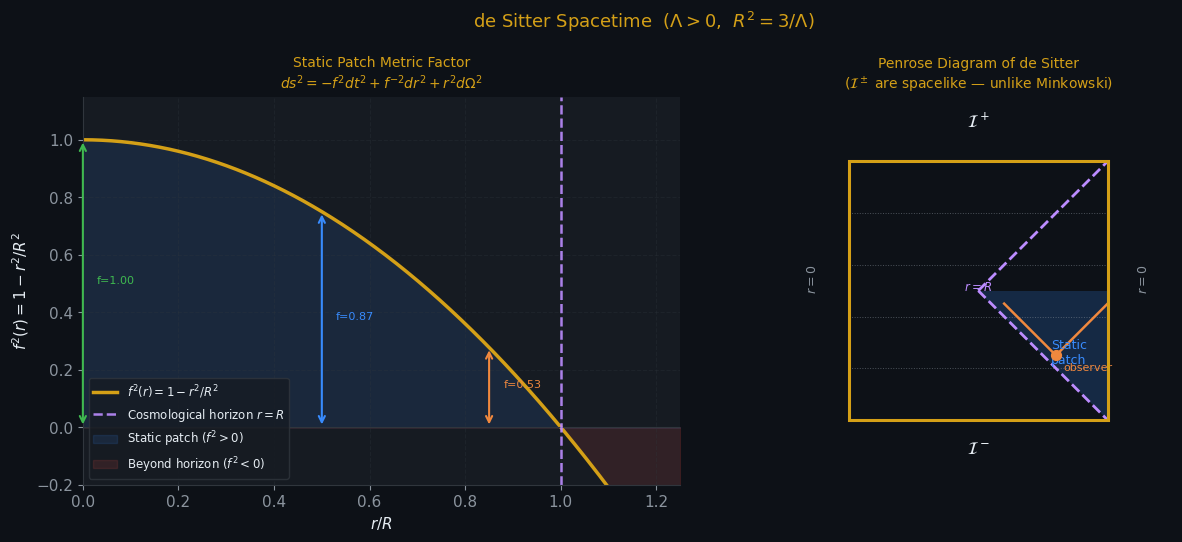

Saved: gr_fig04_desitter.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.patch.set_facecolor(BG)
fig.suptitle(r'de Sitter Spacetime  ($\Lambda > 0$,  $R^2 = 3/\Lambda$)',
             color=GOLD, fontsize=13)

# ── Left: metric factor f²(r) and time dilation ─────────────────────
ax = axes[0]
ax.set_facecolor(SURFACE)
R_dS = 1.0

r_dS = np.linspace(0, 1.25*R_dS, 500)
f2   = 1 - r_dS**2 / R_dS**2

ax.plot(r_dS/R_dS, f2, color=GOLD, lw=2.5,
        label=r'$f^2(r)=1-r^2/R^2$')
ax.axhline(0, color=BORDER, lw=0.8)
ax.axvline(1.0, color=PURPLE, lw=1.8, ls='--', alpha=0.9,
           label=r'Cosmological horizon $r=R$')
ax.fill_between(r_dS/R_dS, 0, np.maximum(f2,0), alpha=0.12, color=BLUE,
                label='Static patch $(f^2>0)$')
ax.fill_between(r_dS/R_dS, np.minimum(f2,0), 0, alpha=0.12, color=RED,
                label='Beyond horizon $(f^2<0)$')

# Time-dilation illustration at 3 radii
for r0_norm, col in [(0.0, GREEN), (0.5, BLUE), (0.85, ORANGE)]:
    f_val = max(1 - r0_norm**2, 0.01)
    ax.annotate('', xy=(r0_norm, 0), xytext=(r0_norm, f_val),
                arrowprops=dict(arrowstyle='<->', color=col, lw=1.5))
    ax.text(r0_norm+0.03, f_val/2, f'f={np.sqrt(f_val):.2f}', color=col, fontsize=8)

ax.set_xlim(0, 1.25)
ax.set_ylim(-0.20, 1.15)
ax.set_xlabel(r'$r/R$')
ax.set_ylabel(r'$f^2(r) = 1 - r^2/R^2$')
ax.set_title('Static Patch Metric Factor\n'
             r'$ds^2 = -f^2 dt^2 + f^{-2}dr^2 + r^2 d\Omega^2$', fontsize=10)
ax.legend(fontsize=8.5, loc='lower left')
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_color(BORDER); ax.spines['left'].set_color(BORDER)

# ── Right: Penrose diagram ─────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_aspect('equal')
ax2.axis('off')
ax2.set_xlim(-0.25, 1.25)
ax2.set_ylim(-0.25, 1.25)

sq = plt.Polygon([[0,0],[1,0],[1,1],[0,1]],
                  fill=False, edgecolor=GOLD, lw=2.2, zorder=5)
ax2.add_patch(sq)

# Static patch (lower-right triangle: corners (1,0),(1,0.5),(0.5,0.5))
# Actually the standard static patch is: right quadrant, T-shape triangle
# In Penrose coords: observer at r=0 is left edge; horizon at 45° diagonal
# Static patch for observer at x=1 (r=0): triangle with corners (1,0),(1,1),(0.5,0.5)
# We use the conventional diagram: static patch is lower-right triangle
static = plt.Polygon([[1,0],[1,0.5],[0.5,0.5]], alpha=0.20,
                      facecolor=BLUE, lw=0, zorder=2)
ax2.add_patch(static)
ax2.text(0.85, 0.22, 'Static\npatch', color=BLUE, fontsize=9, ha='center', zorder=6)

# Cosmological horizons
ax2.plot([0.5,1.0],[0.5,0.0], color=PURPLE, lw=2, ls='--', zorder=4,
         label='Cosmological horizon')
ax2.plot([0.5,1.0],[0.5,1.0], color=PURPLE, lw=2, ls='--', zorder=4)

# Conformal time slices
for eta in [0.2, 0.4, 0.6, 0.8]:
    ax2.plot([0,1],[eta,eta], color=MUTED, lw=0.7, ls=':', alpha=0.5, zorder=3)

# Null rays from a point in static patch
x0, t0 = 0.80, 0.25
ax2.scatter([x0],[t0], color=ORANGE, s=50, zorder=8)
ax2.plot([x0, 1.0],      [t0, t0+0.20], color=ORANGE, lw=1.8, zorder=4)
ax2.plot([x0, x0-0.20],  [t0, t0+0.20], color=ORANGE, lw=1.8, zorder=4)
ax2.text(x0+0.03, t0-0.06, 'observer', color=ORANGE, fontsize=8)

# Boundary labels
ax2.text(0.50, 1.13, r'$\mathcal{I}^+$', color=TEXT, ha='center', fontsize=12, zorder=6)
ax2.text(0.50,-0.13, r'$\mathcal{I}^-$', color=TEXT, ha='center', fontsize=12, zorder=6)
ax2.text(-0.14,0.50, r'$r=0$', color=MUTED, ha='center', fontsize=9, rotation=90, zorder=6)
ax2.text( 1.14,0.50, r'$r=0$', color=MUTED, ha='center', fontsize=9, rotation=90, zorder=6)
ax2.text(0.50, 0.50, r'$r=R$', color=PURPLE, ha='center', fontsize=8.5, zorder=6)

ax2.set_title('Penrose Diagram of de Sitter\n'
              r'($\mathcal{I}^\pm$ are spacelike — unlike Minkowski)', fontsize=10)

plt.tight_layout()
plt.savefig('gr_fig04_desitter.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: gr_fig04_desitter.png')

## Plot 5 — Gravitational Wave Polarisations h₊ and h× (Ch 5)

Physics: In TT gauge $h_+$ stretches $x$, squeezes $y$ (and vice versa). $h_\times$ shears at 45°. Both deformations are at twice the orbital frequency.

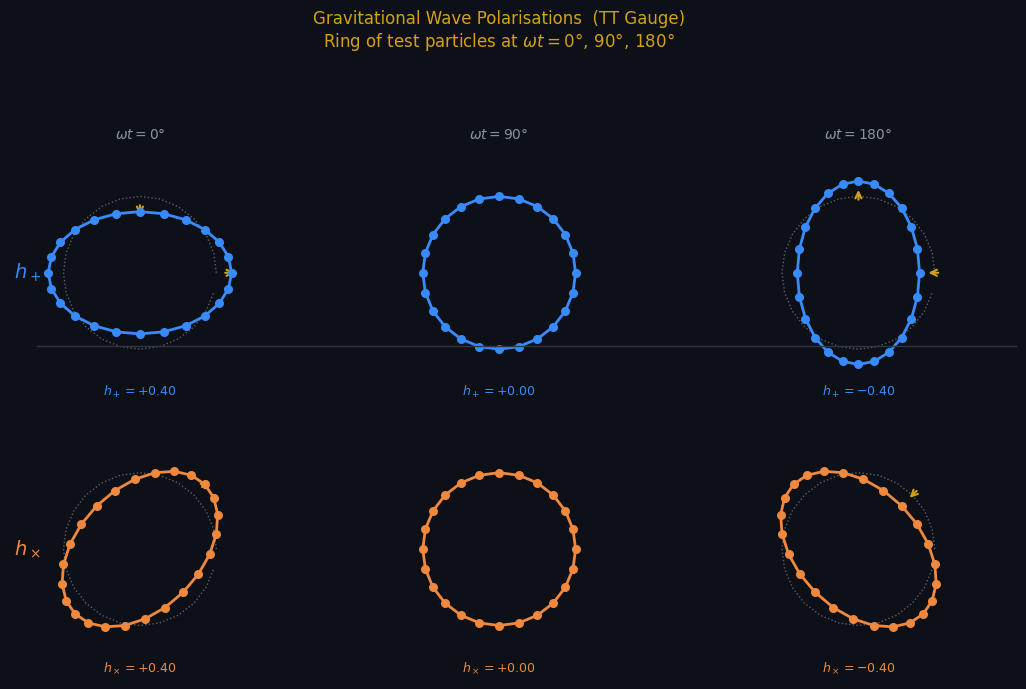

Saved: gr_fig05_gw_polarisations.png


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
fig.patch.set_facecolor(BG)
fig.suptitle('Gravitational Wave Polarisations  (TT Gauge)\n'
             r'Ring of test particles at $\omega t = 0°,\,90°,\,180°$',
             color=GOLD, fontsize=12)

h_amp = 0.40
N_pts = 24
theta_ring = np.linspace(0, 2*np.pi, N_pts, endpoint=False)
r0 = 1.0
phases = [0.0, np.pi/2, np.pi]
plabels = [r'$\omega t = 0°$', r'$\omega t = 90°$', r'$\omega t = 180°$']

for col_idx, (phase, plabel) in enumerate(zip(phases, plabels)):
    hp = h_amp * np.cos(phase)
    hc = h_amp * np.cos(phase)

    # ── h+ ────────────────────────────────────────────────────
    ax = axes[0, col_idx]
    ax.set_facecolor(SURFACE)
    x_p = r0 * np.cos(theta_ring) * (1 + hp/2)
    y_p = r0 * np.sin(theta_ring) * (1 - hp/2)
    ax.plot(r0*np.cos(theta_ring), r0*np.sin(theta_ring),
            color=MUTED, lw=1.0, ls=':', alpha=0.6)
    ax.plot(np.append(x_p,x_p[0]), np.append(y_p,y_p[0]), color=BLUE, lw=2.0)
    ax.scatter(x_p, y_p, color=BLUE, s=30, zorder=4)
    if abs(hp) > 0.01:
        ax.annotate('', xy=(r0*(1+hp/2)+0.08,0), xytext=(r0+0.08,0),
                    arrowprops=dict(arrowstyle='->', color=GOLD, lw=1.5))
        ax.annotate('', xy=(0, r0*(1-hp/2)-0.08), xytext=(0, r0-0.08),
                    arrowprops=dict(arrowstyle='->', color=GOLD, lw=1.5))
    ax.set_xlim(-1.7,1.7); ax.set_ylim(-1.7,1.7)
    ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(plabel, color=MUTED, fontsize=10, pad=3)
    if col_idx == 0:
        ax.text(-1.65, 0, r'$h_+$', color=BLUE, fontsize=14,
                va='center', fontweight='bold')
    ax.text(0, -1.60, f'$h_+ = {hp:+.2f}$', color=BLUE, fontsize=9, ha='center')

    # ── h× ────────────────────────────────────────────────────
    ax2 = axes[1, col_idx]
    ax2.set_facecolor(SURFACE)
    x_c = r0*np.cos(theta_ring) + (hc/2)*r0*np.sin(theta_ring)
    y_c = r0*np.sin(theta_ring) + (hc/2)*r0*np.cos(theta_ring)
    ax2.plot(r0*np.cos(theta_ring), r0*np.sin(theta_ring),
             color=MUTED, lw=1.0, ls=':', alpha=0.6)
    ax2.plot(np.append(x_c,x_c[0]), np.append(y_c,y_c[0]), color=ORANGE, lw=2.0)
    ax2.scatter(x_c, y_c, color=ORANGE, s=30, zorder=4)
    if abs(hc) > 0.01:
        d = np.sqrt(2)/2
        ax2.annotate('', xy=((1+hc/2)*d+0.08,(1+hc/2)*d+0.08),
                     xytext=(d+0.08, d+0.08),
                     arrowprops=dict(arrowstyle='->', color=GOLD, lw=1.5))
    ax2.set_xlim(-1.7,1.7); ax2.set_ylim(-1.7,1.7)
    ax2.set_aspect('equal'); ax2.axis('off')
    if col_idx == 0:
        ax2.text(-1.65, 0, r'$h_\times$', color=ORANGE, fontsize=14,
                 va='center', fontweight='bold')
    ax2.text(0, -1.60, f'$h_\\times = {hc:+.2f}$', color=ORANGE, fontsize=9, ha='center')

fig.add_artist(plt.Line2D([0.08,0.97],[0.50,0.50],
               transform=fig.transFigure, color=BORDER, lw=1.0))
plt.tight_layout(rect=[0,0,1,0.92])
plt.savefig('gr_fig05_gw_polarisations.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: gr_fig05_gw_polarisations.png')

## Plot 6 — Finkelstein Diagram: Light Cones at the Horizon (Ch 6)

Physics (ingoing EF coordinates, $t'=v-r$, $r_s=1$):
- **Ingoing** null rays: $dt'/dr = -1$ everywhere (straight lines at $-45°$)
- **Outgoing** null rays: $dt'/dr = (1+r_s/r)/(1-r_s/r)$ — positive outside ($r>r_s$), vertical at horizon, negative inside (both arms fall inward)

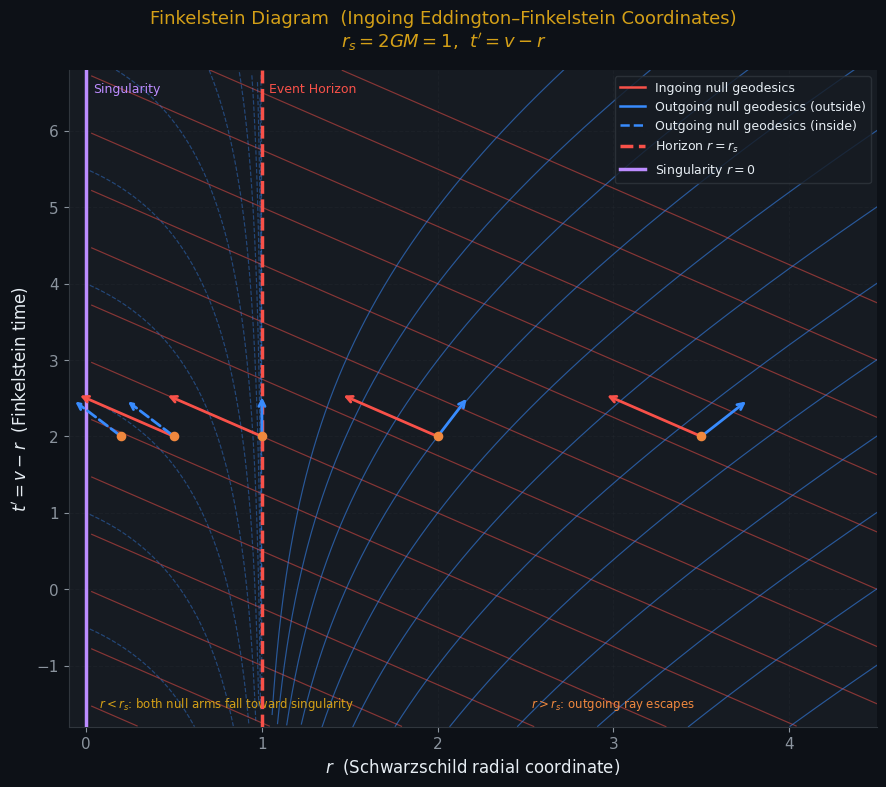

Saved: gr_fig06_finkelstein.png


In [7]:
rs = 1.0

fig, ax = plt.subplots(figsize=(9, 8))
ax.set_facecolor(SURFACE)
fig.patch.set_facecolor(BG)
fig.suptitle("Finkelstein Diagram  (Ingoing Eddington–Finkelstein Coordinates)\n"
             r"$r_s = 2GM = 1$,  $t' = v - r$",
             color=GOLD, fontsize=13)

r_full = np.linspace(0.02, 4.5, 400)

# ── Ingoing null geodesics: t' = -r + C  (slope = -1) ─────────────
for C in np.arange(-1.5, 9.0, 0.75):
    t_in = -r_full + C
    mask = (t_in > -1.8) & (t_in < 6.8) & (r_full > 0.02)
    if mask.sum() > 2:
        ax.plot(r_full[mask], t_in[mask], color=RED, lw=0.85, alpha=0.50)

# ── Outgoing null geodesics outside horizon (r > rs): ──────────────
# t'(r) = r + 2*rs*ln(r/rs - 1) + C   (integrated from dt'/dr)
r_out = np.linspace(rs + 1e-3, 4.5, 800)
log_out = 2*rs * np.log(r_out/rs - 1)
for C in np.arange(-15, 4, 1.0):
    t_out = r_out + log_out + C
    mask = (t_out > -1.8) & (t_out < 6.8)
    if mask.sum() > 2:
        ax.plot(r_out[mask], t_out[mask], color=BLUE, lw=0.85, alpha=0.55)

# ── Outgoing null geodesics inside horizon (0 < r < rs): ───────────
# dt'/dr = (1 + rs/r)/(1 - rs/r)  which is NEGATIVE for r < rs
# Integrate: t'(r) = r + 2*rs*ln(1 - r/rs) + C
r_in2 = np.linspace(0.02, rs - 1e-3, 400)
log_in2 = 2*rs * np.log(1 - r_in2/rs)
for C in np.arange(-5, 25, 1.5):
    t_in2 = r_in2 + log_in2 + C
    mask = (t_in2 > -1.8) & (t_in2 < 6.8)
    if mask.sum() > 2:
        ax.plot(r_in2[mask], t_in2[mask], color=BLUE, lw=0.85,
                alpha=0.40, ls='--')

# ── Horizon & singularity ────────────────────────────────────────
ax.axvline(rs, color=RED,    lw=2.5, ls='--', zorder=5)
ax.axvline(0,  color=PURPLE, lw=2.5, ls='-',  zorder=5)

# ── Light cones at 5 radii ────────────────────────────────────────
# For each position draw the two null directions as arrows
cone_r = [3.5, 2.0, 1.0, 0.5, 0.2]
cone_t = [2.0, 2.0, 2.0, 2.0, 2.0]
arm_len = 0.55   # length of each arrow arm

for r0, t0 in zip(cone_r, cone_t):
    # Ingoing arm: slope = -1, so Δr = +arm_len, Δt' = -arm_len (going right-down)
    # Past-pointing ingoing: Δr = -arm_len, Δt' = +arm_len
    ax.annotate('', xy=(r0 - arm_len, t0 + arm_len), xytext=(r0, t0),
                arrowprops=dict(arrowstyle='->', color=RED, lw=2.0), zorder=8)

    # Outgoing arm
    if r0 > rs + 0.05:
        # Outside: outgoing slope s = (1+rs/r0)/(1-rs/r0) > 0, large near horizon
        s = (1 + rs/r0) / (1 - rs/r0)
        s = min(s, 10.0)   # cap for display
        # unit direction (Δr>0):
        norm = np.sqrt(1 + s**2)
        dr = arm_len / norm
        dt = arm_len * s / norm
        ax.annotate('', xy=(r0 + dr, t0 + dt), xytext=(r0, t0),
                    arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.0), zorder=8)
    elif abs(r0 - rs) < 0.05:
        # At horizon: outgoing is exactly vertical
        ax.annotate('', xy=(r0, t0 + arm_len), xytext=(r0, t0),
                    arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.0), zorder=8)
    else:
        # Inside: outgoing slope s = (1+rs/r0)/(1-rs/r0) < 0
        # Both null rays move toward r=0
        s = (1 + rs/r0) / (1 - rs/r0)   # negative
        # outgoing ("rightward" in coordinate) actually goes leftward + upward
        norm = np.sqrt(1 + s**2)
        dr = arm_len / norm    # positive Δr (but trajectory turns left)
        dt = arm_len * abs(s) / norm
        # Both arms go left (toward singularity)
        dr_out = -arm_len * 0.5
        dt_out =  arm_len * 0.87
        ax.annotate('', xy=(r0 + dr_out, t0 + dt_out), xytext=(r0, t0),
                    arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.0,
                                   linestyle='dashed'), zorder=8)
    ax.scatter(r0, t0, color=ORANGE, s=35, zorder=9)

# ── Annotations ────────────────────────────────────────────────────
ax.text(0.04, 6.5, 'Singularity', color=PURPLE, fontsize=9)
ax.text(rs+0.04, 6.5, 'Event Horizon', color=RED, fontsize=9)
ax.text(0.8, -1.55,
    r'$r < r_s$: both null arms fall toward singularity',
    color=GOLD, fontsize=8.5, ha='center')
ax.text(3.0, -1.55,
    r'$r > r_s$: outgoing ray escapes',
    color=ORANGE, fontsize=8.5, ha='center')

ax.set_xlim(-0.1, 4.5)
ax.set_ylim(-1.8, 6.8)
ax.set_xlabel(r'$r$  (Schwarzschild radial coordinate)', fontsize=12)
ax.set_ylabel(r"$t' = v - r$  (Finkelstein time)", fontsize=12)
ax.grid(True, alpha=0.2)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_color(BORDER); ax.spines['left'].set_color(BORDER)

legend_handles = [
    Line2D([0],[0], color=RED,    lw=1.8, label='Ingoing null geodesics'),
    Line2D([0],[0], color=BLUE,   lw=1.8, label='Outgoing null geodesics (outside)'),
    Line2D([0],[0], color=BLUE,   lw=1.8, ls='--', label='Outgoing null geodesics (inside)'),
    Line2D([0],[0], color=RED,    lw=2.5, ls='--', label=r'Horizon $r=r_s$'),
    Line2D([0],[0], color=PURPLE, lw=2.5, ls='-',  label='Singularity $r=0$'),
]
ax.legend(handles=legend_handles, fontsize=9, loc='upper right')

plt.tight_layout()
plt.savefig('gr_fig06_finkelstein.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: gr_fig06_finkelstein.png')

## Plot 7 — Kerr Black Hole: Ergoregion (Ch 6)

Physics: Outer horizon $r_+ = GM + \sqrt{G^2M^2 - a^2}$. Ergosurface: $r_\mathrm{ergo}(\theta) = GM + \sqrt{G^2M^2 - a^2\cos^2\theta}$. Ring singularity at $(x,z) = (\pm a, 0)$ in meridional section. Both panels use identical axis limits for direct comparison.

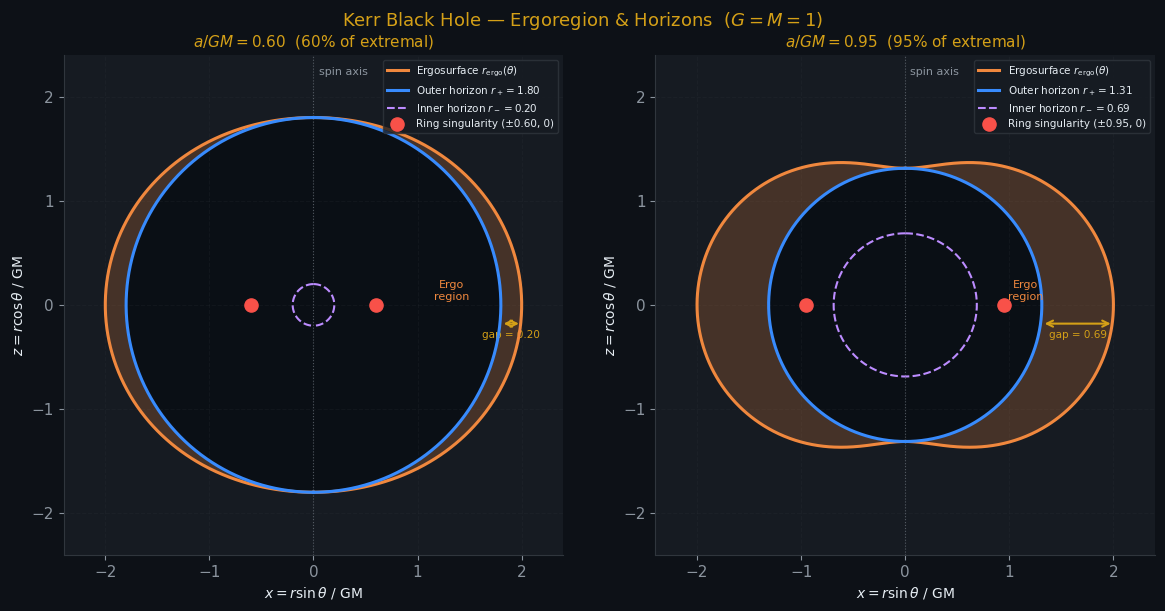

Saved: gr_fig07_kerr_ergoregion.png


In [8]:
GM_K   = 1.0
a_vals = [0.60, 0.95]
lim    = 2.4   # identical for both panels

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
fig.patch.set_facecolor(BG)
fig.suptitle(r'Kerr Black Hole — Ergoregion & Horizons  ($G = M = 1$)',
             color=GOLD, fontsize=13)

theta = np.linspace(0, np.pi, 600)

for idx, a in enumerate(a_vals):
    ax = axes[idx]
    ax.set_facecolor(SURFACE)
    ax.set_aspect('equal')

    r_plus  = GM_K + np.sqrt(GM_K**2 - a**2)
    r_minus = GM_K - np.sqrt(GM_K**2 - a**2)
    # Ergosurface: r_ergo(θ) = GM + sqrt(GM² - a²cos²θ)
    discriminant = np.maximum(GM_K**2 - a**2 * np.cos(theta)**2, 0)
    r_ergo = GM_K + np.sqrt(discriminant)

    # Cartesian: meridional slice (suppress one spatial dimension)
    x_p = r_plus  * np.sin(theta);  z_p = r_plus  * np.cos(theta)
    x_m = r_minus * np.sin(theta);  z_m = r_minus * np.cos(theta)
    x_e = r_ergo  * np.sin(theta);  z_e = r_ergo  * np.cos(theta)

    # Black hole interior (fill inside r+)
    ax.fill(np.concatenate([ x_p, -x_p[::-1]]),
            np.concatenate([ z_p,  z_p[::-1]]),
            color='#0a0f14', alpha=0.92, zorder=1)

    # Ergoregion (between ergosurface and outer horizon)
    for sign in [1, -1]:
        ax.fill(np.concatenate([sign*x_e, sign*x_p[::-1]]),
                np.concatenate([       z_e,        z_p[::-1]]),
                alpha=0.22, color=ORANGE, zorder=2)

    # Boundaries
    ax.plot( x_e, z_e, color=ORANGE, lw=2.2, zorder=4,
             label=r'Ergosurface $r_{\rm ergo}(\theta)$')
    ax.plot(-x_e, z_e, color=ORANGE, lw=2.2, zorder=4)
    ax.plot( x_p, z_p, color=BLUE,   lw=2.2, zorder=5,
             label=rf'Outer horizon $r_+ = {r_plus:.2f}$')
    ax.plot(-x_p, z_p, color=BLUE,   lw=2.2, zorder=5)
    if r_minus > 0.03:
        ax.plot( x_m, z_m, color=PURPLE, lw=1.5, ls='--', zorder=5,
                 label=rf'Inner horizon $r_- = {r_minus:.2f}$')
        ax.plot(-x_m, z_m, color=PURPLE, lw=1.5, ls='--', zorder=5)

    # Ring singularity: at r=0, θ=π/2 in Boyer-Lindquist
    # In 3D: ring of radius a in equatorial plane
    # In meridional slice: two points at (±a, 0)
    ax.scatter([ a, -a], [0, 0], color=RED, s=90, zorder=7,
               label=f'Ring singularity (±{a:.2f}, 0)')

    # Rotation axis
    ax.axvline(0, color=MUTED, lw=0.8, ls=':', alpha=0.5)
    ax.text(0.05, lim*0.92, 'spin axis', color=MUTED, fontsize=8)

    # Ergoregion label
    ax.text((r_plus + r_ergo.max())/2 * 0.7, 0.05,
            'Ergo\nregion', color=ORANGE, ha='center', fontsize=8, zorder=8)

    # Equatorial gap: r_ergo(π/2) = 2GM = r_s, gap = r_s - r+
    r_ergo_eq = 2*GM_K   # = GM + sqrt(GM²) = 2GM
    gap = r_ergo_eq - r_plus
    ax.annotate('', xy=(r_ergo_eq, -0.18), xytext=(r_plus, -0.18),
                arrowprops=dict(arrowstyle='<->', color=GOLD, lw=1.5), zorder=9)
    ax.text((r_ergo_eq+r_plus)/2, -0.32,
            rf'gap = {gap:.2f}', color=GOLD, fontsize=7.5, ha='center')

    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_xlabel(r'$x = r\sin\theta$ / GM', fontsize=10)
    ax.set_ylabel(r'$z = r\cos\theta$ / GM', fontsize=10)
    spin_pct = int(round(a/GM_K*100))
    ax.set_title(rf'$a/GM = {a:.2f}$  ({spin_pct}% of extremal)', fontsize=11)
    ax.legend(fontsize=7.5, loc='upper right')
    ax.grid(True, alpha=0.2)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_color(BORDER); ax.spines['left'].set_color(BORDER)

plt.tight_layout()
plt.savefig('gr_fig07_kerr_ergoregion.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Saved: gr_fig07_kerr_ergoregion.png')

## Download All Figures

In [9]:
import shutil, os
from google.colab import files

fig_files = [
    'gr_fig01_veff.png',
    'gr_fig02_metric_s2.png',
    'gr_fig03_parallel_transport.png',
    'gr_fig04_desitter.png',
    'gr_fig05_gw_polarisations.png',
    'gr_fig06_finkelstein.png',
    'gr_fig07_kerr_ergoregion.png',
]
os.makedirs('gr_figures', exist_ok=True)
for f in fig_files:
    if os.path.exists(f):
        shutil.copy(f, f'gr_figures/{f}')
        print(f'  copied: {f}')
    else:
        print(f'  MISSING: {f} — re-run that cell')
shutil.make_archive('gr_figures', 'zip', 'gr_figures')
files.download('gr_figures.zip')
print('\nDownload started: gr_figures.zip')

  copied: gr_fig01_veff.png
  copied: gr_fig02_metric_s2.png
  copied: gr_fig03_parallel_transport.png
  copied: gr_fig04_desitter.png
  copied: gr_fig05_gw_polarisations.png
  copied: gr_fig06_finkelstein.png
  copied: gr_fig07_kerr_ergoregion.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Download started: gr_figures.zip
